# 1. Project Framing

You are a **People Analytics consultant**. Your goal is to predict **employee Attrition** (whether an employee will leave the company) based on various demographic, job-related, and financial factors.

---

## Dataset

**HR Analytics (Employee Attrition)**

This dataset contains employee-level records with attributes such as:

- Demographic information (e.g., age, gender, marital status)  
- Job-related features (e.g., department, role, job level, years at company)  
- Financial information (e.g., monthly income, stock option level)  
- Work environment and performance indicators (e.g., job satisfaction, overtime, training times)  

---

## Task
- Each employee is classified into one of two categories:
  - **Yes**:  Employee will leave the company  
  - **No**:   Employee will stay at the company  

---

## Target Variable

**Attrition**  
- Values: `Yes`, `No`  
- Interpretation:
  - `Yes` = Employee has left or is expected to leave  
  - `No`  = Employee remains with the company  

---

## High-Level Rubric
| Section                   | Points | Key Requirements for Full Marks |
|---------------------------|--------|---------------------------------|
| 1. Project Framing        | 5      | Correctly identify the classification problem type and provide a logical justification for the relative cost of **False Positives vs. False Negatives** in the HR context. |
| 2. Data Acquisition       | 5      | Successfully load the CSV dataset and identify **redundant or non-informative features**. |
| 3. Manual EDA & Cleaning  | 10     | Provide high-quality visualizations of the **target distribution** and key predictors. Correctly map the target variable to numeric format. Perform a **thoughtful correlation and missing value analysis**. |
| 4. Model Development      | 10     | Correctly implement a **ColumnTransformer** for scaling numerical features and encoding categorical features. Compare the **DummyClassifier baseline** to a **Logistic Regression model** using proper evaluation metrics. |
| 5. Performance Analysis   | 10     | Generate a **Confusion Matrix** and **Precision-Recall curve**. Provide a clear explanation of why **accuracy alone is insufficient** for this imbalanced dataset. |
| 6. Imbalance Handling     | 10     | Successfully apply **class_weight** to handle class imbalance. Perform **manual threshold tuning** to achieve a target **Recall** and discuss the impact on Precision and F1-score. |


## Detailed Scoring Guide

| Section                   | Task / Requirement            | Points | Criteria for Obtaining Points                                                                                     |
|---------------------------|-------------------------------|--------|------------------------------------------------------------------------------------------------------------------|
| 1. Project Framing        | Problem Definition            | 2      | Correctly identify the type of classification problem.      |
|                           | Business Logic                | 3      | Discuss relative costs of **False Positives vs. False Negatives** in HR context.                                 |
| 2. Data Acquisition       | Initial Inspection            | 2      | Load dataset, inspect `.info()`, identify missing values, and confirm structural integrity.                       |
|                           | Feature Selection             | 3      | Identify and remove **non-informative or redundant features** (e.g., zero-variance columns, IDs).                |
| 3. Manual EDA & Cleaning  | Target Analysis               | 2      | Compute and visualize **target distribution**, map target to numeric format.                                     |
|                           | Predictor Analysis            | 4      | Explore relationships between predictors and target via at least **2 visualizations**; discuss business impact. |
|                           | Data Cleaning & Imputation    | 4      | Handle missing values (e.g., impute `YearsWithCurrManager`), check for inconsistencies, ensure dataset quality. |
| 4. Model Development      | Preprocessing Pipeline        | 4      | Implement **ColumnTransformer** for numerical scaling and categorical encoding; ensure reproducibility.         |
|                           | Experimental Setup            | 2      | Split data into training/testing sets with **stratification** and fixed random seed.                              |
|                           | Baseline vs Predictive Model  | 4      | Train **DummyClassifier** baseline and **Logistic Regression**; compare metrics.                                 |
| 5. Performance Analysis   | Metric Computation & Visualization | 6  | Compute **Precision, Recall, F1-score**; plot **Confusion Matrix** and **Precision-Recall Curve**.               |
|                           | Model Interpretation          | 4      | Discuss results in terms of HR business impact; highlight costly False Negatives and model limitations.          |
| 6. Imbalance Handling     | Class Weight Adjustment       | 3      | Retrain model using `class_weight='balanced'`; evaluate improvement in Recall.                                   |
|                           | Threshold Tuning              | 4      | Adjust decision threshold to target **Recall >= 0.75**; report corresponding F1-score.                             |
|                           | Final Evaluation & Discussion | 3      | Compare metrics before and after tuning; discuss trade-offs between Precision and Recall.                         |
| **TOTAL**                 |                               | **50** |                                                                                                                  |

---

## **Important Note:** 
While you should follow these guidelines as a foundational roadmap for your project, you are highly encouraged to go beyond the specific requirements. Feel free to implement your own creative ideas, explore additional feature engineering, test alternative algorithms, or apply advanced optimization techniques to improve your final results and insights.

---

### <font color="darkred">**Question 1:**</font>

In the context of HR analytics, which is more costly:

- A **False Positive** (predicting an employee will leave when they intend to stay), or  
- A **False Negative** (predicting an employee will stay when they intend to leave)?

---

How does this affect your choice of a performance metric for this specific task?</font>  

---

# 2. Data Acquisition & Initial Inspection

Load the dataset and perform a high-level audit to identify:

- Useless features (e.g., constant-value columns, unique identifiers)  
- Potential data quality issues  
- Schema inconsistencies and missing values  

This step ensures the dataset is structurally sound before proceeding to preprocessing and modeling.

---

### <font color="darkred">**Question 2**</font>

After running `.info()` and `.nunique()`, you will notice that some columns:

- Have the **same value for every single row**, or  
- Act as **unique identifiers** (e.g., Employee ID).

---

Why should these features be removed before training a machine learning model?   

---



In [1]:
import pandas as pd
import numpy as np
import os
from IPython.display import display

# 1. Load the CSV using encoding='UTF-8-SIG'
#    (Your assignment prompt says 'HR_Analytics.csv', but the provided file is 'asn_01_classification_data.csv'.)
# 2. Display the first 10 rows and the .info() summary.
# 3. Identify and drop columns that provide no predictive power.

DATA_PATH_CANDIDATES = [
    "asn_01_classification_data2.csv",
    "HR_Analytics.csv",
    "/mnt/data/asn_01_classification_data.csv",  # (only relevant if you're running inside this sandbox)
    "/mnt/data/HR_Analytics.csv",
]

data_path = next((p for p in DATA_PATH_CANDIDATES if os.path.exists(p)), None)

if data_path is None:
    raise FileNotFoundError(
        "Could not find the dataset. Put 'asn_01_classification_data.csv' in the same folder as this notebook "
        "or rename it to 'HR_Analytics.csv'."
    )

df = pd.read_csv(data_path, encoding="UTF-8-SIG")

print(f"✅ Loaded dataset: {data_path} | shape={df.shape}")
display(df.head(10))

print("\n--- df.info() ---")
df.info()

print("\n--- nunique() audit (useful for spotting IDs/constants) ---")
nunique = df.nunique(dropna=False).sort_values()
display(nunique.to_frame("n_unique"))

# Drop columns that provide no predictive power: constants + ID
drop_cols = [c for c in ["StandardHours", "EmployeeCount", "Over18", "EmpID"] if c in df.columns]
print("\nDropping non-predictive columns:", drop_cols)
df = df.drop(columns=drop_cols)

print("\nAfter dropping non-predictive columns:")
print("shape:", df.shape)


✅ Loaded dataset: asn_01_classification_data2.csv | shape=(1480, 38)


,EmpID,Age,AgeGroup,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,RM297,18,18-25,Yes,Travel_Rarely,230,Research & Development,3,3,Life Sciences,...,3,80,0,0,2,3,0,0,0,0.0
1,RM302,18,18-25,No,Travel_Rarely,812,Sales,10,3,Medical,...,1,80,0,0,2,3,0,0,0,0.0
2,RM458,18,18-25,Yes,Travel_Frequently,1306,Sales,5,3,Marketing,...,4,80,0,0,3,3,0,0,0,0.0
3,RM728,18,18-25,No,Non-Travel,287,Research & Development,5,2,Life Sciences,...,4,80,0,0,2,3,0,0,0,0.0
4,RM829,18,18-25,Yes,Non-Travel,247,Research & Development,8,1,Medical,...,4,80,0,0,0,3,0,0,0,0.0
5,RM973,18,18-25,No,Non-Travel,1124,Research & Development,1,3,Life Sciences,...,3,80,0,0,5,4,0,0,0,0.0
6,RM1154,18,18-25,Yes,Travel_Frequently,544,Sales,3,2,Medical,...,3,80,0,0,2,4,0,0,0,0.0
7,RM1312,18,18-25,No,Non-Travel,1431,Research & Development,14,3,Medical,...,3,80,0,0,4,1,0,0,0,0.0
8,RM128,19,18-25,Yes,Travel_Rarely,528,Sales,22,1,Marketing,...,4,80,0,0,2,2,0,0,0,0.0
9,RM150,19,18-25,No,Travel_Rarely,1181,Research & Development,3,1,Medical,...,4,80,0,1,3,3,1,0,0,0.0



--- df.info() ---
<class 'pandas.DataFrame'>
RangeIndex: 1480 entries, 0 to 1479
Data columns (total 38 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmpID                     1480 non-null   str    
 1   Age                       1480 non-null   int64  
 2   AgeGroup                  1480 non-null   str    
 3   Attrition                 1480 non-null   str    
 4   BusinessTravel            1480 non-null   str    
 5   DailyRate                 1480 non-null   int64  
 6   Department                1480 non-null   str    
 7   DistanceFromHome          1480 non-null   int64  
 8   Education                 1480 non-null   int64  
 9   EducationField            1480 non-null   str    
 10  EmployeeCount             1480 non-null   int64  
 11  EmployeeNumber            1480 non-null   int64  
 12  EnvironmentSatisfaction   1480 non-null   int64  
 13  Gender                    1480 non-null   str    
 14  

,n_unique
Over18,1
StandardHours,1
EmployeeCount,1
Gender,2
PerformanceRating,2
Attrition,2
OverTime,2
Department,3
MaritalStatus,3
SalarySlab,4



Dropping non-predictive columns: ['StandardHours', 'EmployeeCount', 'Over18', 'EmpID']

After dropping non-predictive columns:
shape: (1480, 34)


# 3. Data Cleaning & Exploratory Analysis

## Task 3.1: Perform a structured data quality review

- Identify and quantify missing values  
- Audit features for redundancy or zero variance  
- Make defensible preprocessing decisions prior to modeling  

This step establishes a clean and analytically sound feature set.

---

### Expected Actions

1. Print the full list of dataset columns.  
2. Compute and display the **count and percentage of null values** for each feature.  
3. Flag any features containing missing data for further review.

---


In [2]:
from IPython.display import display

# 1) Print all columns
print("Columns ({}):".format(len(df.columns)))
print(df.columns.tolist())

# 2) Calculate and display the count + percentage of null values per column
null_count = df.isna().sum().sort_values(ascending=False)
null_pct = (df.isna().mean() * 100).sort_values(ascending=False)

null_report = pd.DataFrame({"null_count": null_count, "null_pct": null_pct})
display(null_report)

# 3) Drop 'StandardHours', 'EmployeeCount', 'Over18', and 'EmpID' (safe even if already dropped)
drop_cols = [c for c in ["StandardHours", "EmployeeCount", "Over18", "EmpID"] if c in df.columns]
if drop_cols:
    print("Dropping:", drop_cols)
    df = df.drop(columns=drop_cols)
else:
    print("✅ These columns are already removed (or not present).")


Columns (34):
['Age', 'AgeGroup', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'SalarySlab', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


,null_count,null_pct
YearsWithCurrManager,57,3.851351
RelationshipSatisfaction,0,0.000000
SalarySlab,0,0.000000
MonthlyRate,0,0.000000
NumCompaniesWorked,0,0.000000
OverTime,0,0.000000
PercentSalaryHike,0,0.000000
PerformanceRating,0,0.000000
StockOptionLevel,0,0.000000
AgeGroup,0,0.000000


✅ These columns are already removed (or not present).


## Task 3.2: Target Variable Analysis (Attrition)

Examine the distribution of the target variable (**Attrition**) to:

- Understand class proportions  
- Detect potential class imbalance  
- Anticipate modeling challenges related to skewed class distributions  

This analysis is foundational for selecting appropriate evaluation metrics and modeling strategies.

---

### Expected Actions

1. Compute and display the **frequency counts** of each Attrition class (`Yes` vs. `No`). 
2. Calculate the **percentage distribution** of each class.  
3. Visualize the class distribution using a **bar chart**.
4. Map the target variable Attrition to a numerical format (Yes = 1, No = 0) for downstream analysis (if you see it required).

---

### Visualization Quality Requirements:
- Clear axis labels  
- Informative titles  
- Appropriate figure size  
- Legends where applicable  
- Readable color contrast  
- Proper tick formatting  


---

,count,pct
Attrition,,
No,1242,83.92
Yes,238,16.08


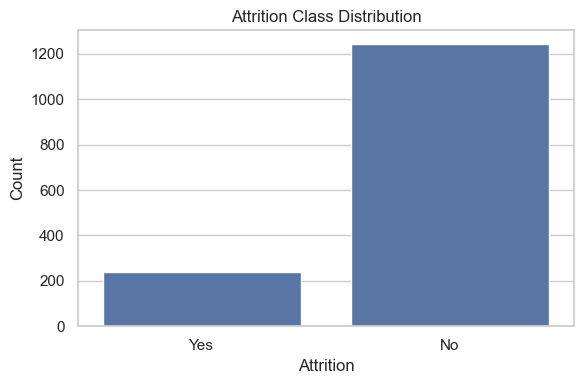

Imbalance ratio (No / Yes) = 5.22


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1) Value counts + percentages for target
attr_counts = df["Attrition"].value_counts(dropna=False)
attr_pct = df["Attrition"].value_counts(normalize=True, dropna=False) * 100

target_summary = pd.DataFrame({"count": attr_counts, "pct": attr_pct.round(2)})
display(target_summary)

# 2) Countplot
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Attrition")
plt.title("Attrition Class Distribution")
plt.xlabel("Attrition")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print(f"Imbalance ratio (No / Yes) = {attr_counts.get('No', np.nan) / attr_counts.get('Yes', np.nan):.2f}")


## Task 3.3: Deep Dive into Key Predictors

Investigate how key features influence **Attrition** in order to:

- Identify patterns and trends among employees who leave vs. those who stay  
- Quantify potential risk factors  
- Inform feature selection and modeling strategies  

Focus features:

- **Numerical:** Age, MonthlyIncome  
- **Categorical:** Gender, Department, JobRole, OverTime  

---

### Expected Actions

1. **Categorical Features**  
   - Calculate **Attrition Rate per category**.   
   - Use bar charts or pivot tables for visualization.  


2. **Numerical Features**  
   - Compare distributions for employees who **stayed** vs. **left**.  
   - Use **Boxplots** or **Kernel Density Estimates (KDE)**.  
   - Highlight differences in medians, spreads, and outliers.  

---

### Notes

- Use **groupby()** or **pivot tables** for categorical features.  
- Use **seaborn** or **matplotlib** for visualization:  
  - `sns.boxplot()`  
  - `sns.kdeplot()`  
- Document both **observations** and **potential business impact** to justify modeling decisions.  

---

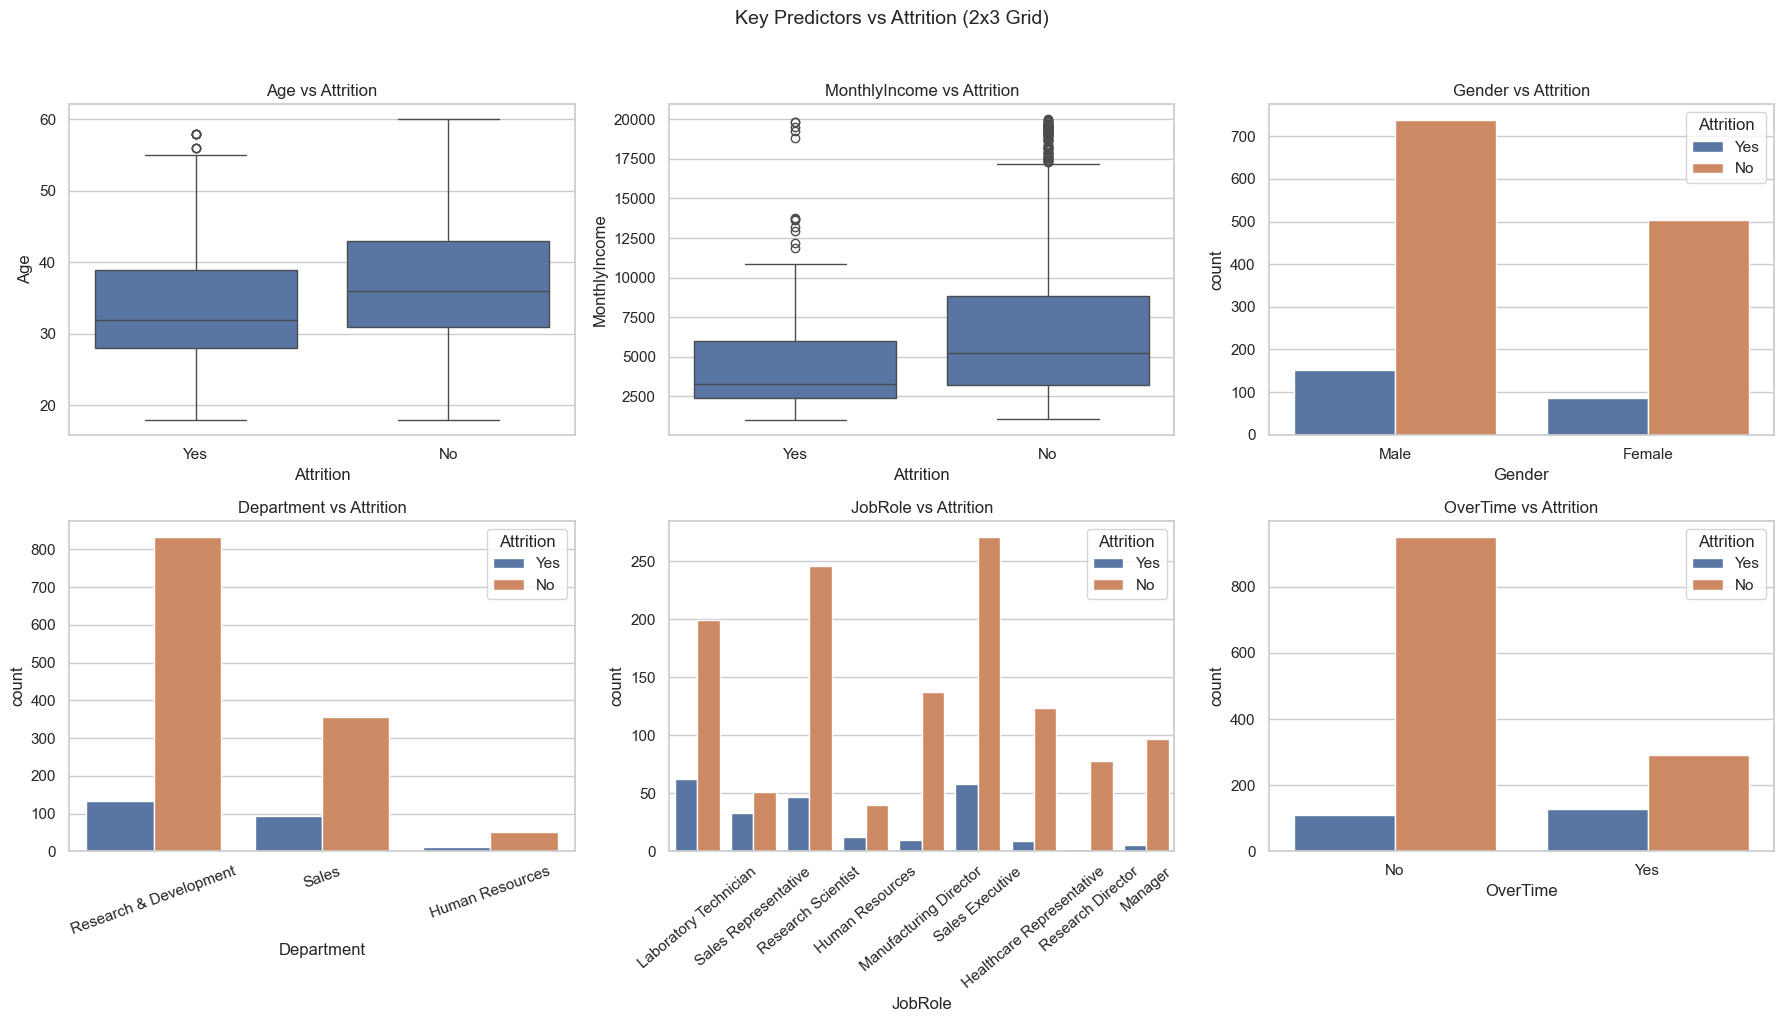


Attrition rate (%) by Gender:


,Gender,rate_pct
3,Male,16.99
1,Female,14.72



Attrition rate (%) by Department:


,Department,rate_pct
5,Sales,20.67
1,Human Resources,19.05
3,Research & Development,13.75



Attrition rate (%) by JobRole:


,JobRole,rate_pct
17,Sales Representative,39.29
5,Laboratory Technician,23.75
3,Human Resources,23.08
15,Sales Executive,17.63
13,Research Scientist,16.04
1,Healthcare Representative,6.82
9,Manufacturing Director,6.80
7,Manager,4.90
11,Research Director,2.50



Attrition rate (%) by OverTime:


,OverTime,rate_pct
3,Yes,30.62
1,No,10.36


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Features requested in the prompt:
# Numerical: Age, MonthlyIncome
# Categorical: Gender, Department, JobRole, OverTime

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# 1) Age vs Attrition (boxplot)
sns.boxplot(data=df, x="Attrition", y="Age", ax=axes[0])
axes[0].set_title("Age vs Attrition")

# 2) MonthlyIncome vs Attrition (boxplot)
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome", ax=axes[1])
axes[1].set_title("MonthlyIncome vs Attrition")

# 3) Gender vs Attrition (countplot)
sns.countplot(data=df, x="Gender", hue="Attrition", ax=axes[2])
axes[2].set_title("Gender vs Attrition")
axes[2].legend(title="Attrition")

# 4) Department vs Attrition (countplot)
sns.countplot(data=df, x="Department", hue="Attrition", ax=axes[3])
axes[3].set_title("Department vs Attrition")
axes[3].tick_params(axis="x", rotation=20)
axes[3].legend(title="Attrition")

# 5) JobRole vs Attrition (countplot)
sns.countplot(data=df, x="JobRole", hue="Attrition", ax=axes[4])
axes[4].set_title("JobRole vs Attrition")
axes[4].tick_params(axis="x", rotation=40)
axes[4].legend(title="Attrition")

# 6) OverTime vs Attrition (countplot)
sns.countplot(data=df, x="OverTime", hue="Attrition", ax=axes[5])
axes[5].set_title("OverTime vs Attrition")
axes[5].legend(title="Attrition")

plt.suptitle("Key Predictors vs Attrition (2x3 Grid)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# Attrition rate per category (for the 4 categorical predictors)
def attrition_rate_table(col: str) -> pd.DataFrame:
    tmp = df.groupby(col)["Attrition"].value_counts(normalize=True).rename("rate").reset_index()
    # keep only rate of Yes
    tmp_yes = tmp[tmp["Attrition"] == "Yes"].drop(columns=["Attrition"]).sort_values("rate", ascending=False)
    tmp_yes["rate_pct"] = (tmp_yes["rate"] * 100).round(2)
    return tmp_yes[[col, "rate_pct"]]

for col in ["Gender", "Department", "JobRole", "OverTime"]:
    print(f"\nAttrition rate (%) by {col}:")
    display(attrition_rate_table(col))


## Task 3.4: Feature Correlation & Histogram Matrix

Analyze numerical relationships in the dataset to:

- Identify features most strongly correlated with **Attrition**  
- Validate insights from the previous deep-dive analysis (Task 3.3)  
- Detect multicollinearity that may affect model performance  

---

### Expected Actions

1. **Correlation Heatmap**  
   - Convert the target variable **Attrition** into a numerical format: `Yes=1`, `No=0` (if you have not done so yet)  
   - Compute the **correlation matrix** between Attrition and other numerical features.  
   - Visualize using a **heatmap** (e.g., with `seaborn.heatmap`).  

2. **Histogram-Based Heatmap / Pairplot**  
   - Select the **4–5 features most correlated** with Attrition.  
   - Create a **pairplot** or histogram matrix, color-coded by the target variable.  
   - Use this to visualize distributions, overlaps, and potential thresholds.

---

### Notes

- Use **`df.corr()`** for correlation calculation.  
- Use **`sns.heatmap()`** for a visual correlation matrix.  
- Use **`sns.pairplot()`** with `hue='Attrition'` for the histogram matrix.  
- Focus discussion on business relevance and predictive power rather than only numerical values.  

---

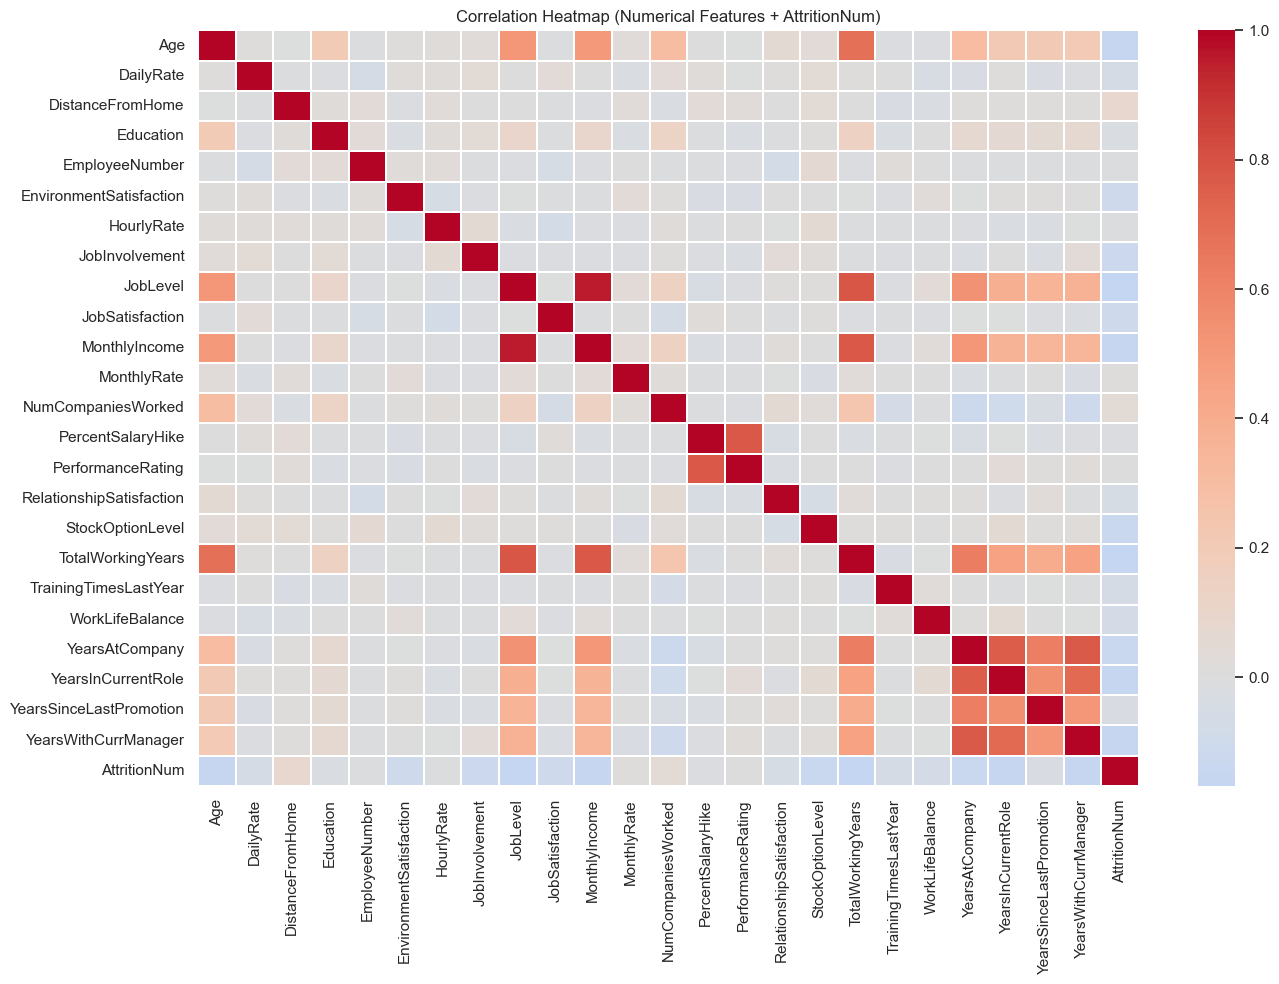


Top 10 numerical correlations with Attrition (absolute):


,abs_corr_with_Attrition
TotalWorkingYears,0.168358
JobLevel,0.167150
YearsWithCurrManager,0.163367
YearsInCurrentRole,0.160968
MonthlyIncome,0.157672
Age,0.155476
StockOptionLevel,0.135140
YearsAtCompany,0.135108
JobInvolvement,0.130769
JobSatisfaction,0.104232


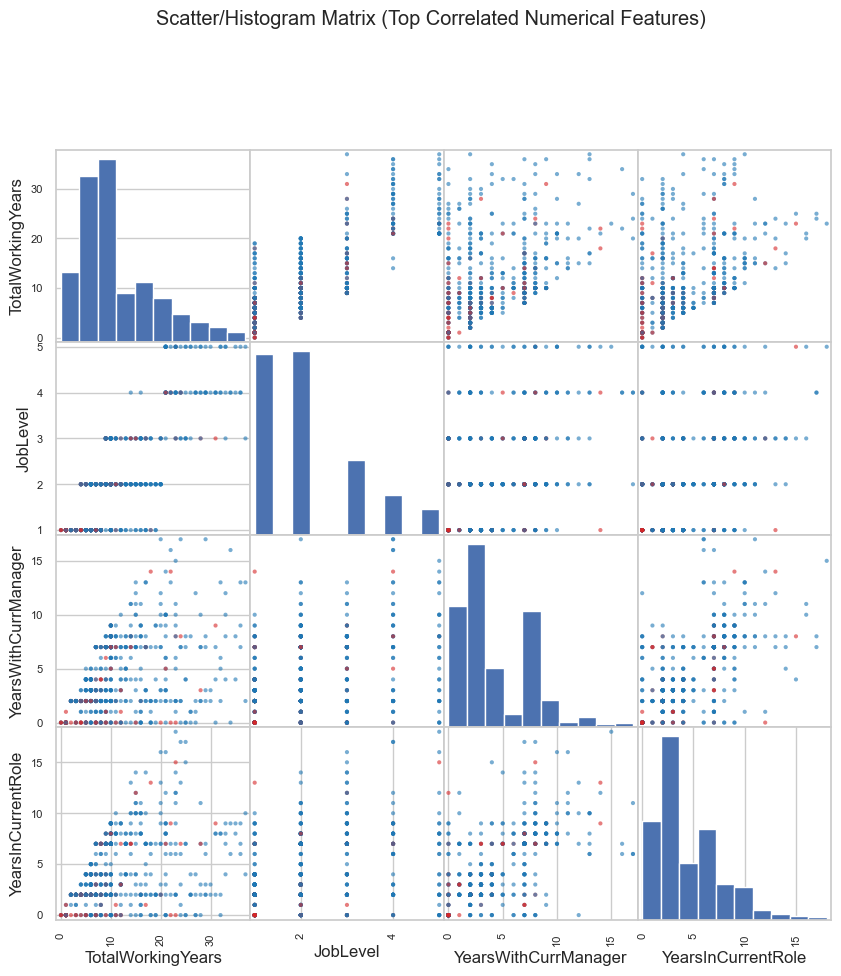

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from pandas.plotting import scatter_matrix

sns.set_theme(style="whitegrid")

# 1) Map 'Attrition' to numeric for correlation
if "AttritionNum" not in df.columns:
    df["AttritionNum"] = df["Attrition"].map({"Yes": 1, "No": 0})

# 2) Correlation heatmap (numerical only)
num_df = df.select_dtypes(include=[np.number]).copy()
corr = num_df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.1)
plt.title("Correlation Heatmap (Numerical Features + AttritionNum)")
plt.tight_layout()
plt.show()

# Show top correlations with AttritionNum for interpretability
top_corr = (
    corr["AttritionNum"]
    .drop("AttritionNum")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

print("\nTop 10 numerical correlations with Attrition (absolute):")
display(top_corr.abs().head(10).to_frame("abs_corr_with_Attrition"))

# 3) Histogram/Scatter matrix (pairplot-like) without seaborn.pairplot
# Choose the top 4 correlated numerical features
pair_features = top_corr.abs().head(4).index.tolist()

df_pair = df[pair_features + ["Attrition"]].dropna().copy()
if len(df_pair) > 600:
    df_pair = df_pair.sample(600, random_state=42)

colors = df_pair["Attrition"].map({"Yes": "tab:red", "No": "tab:blue"}).values

axs = scatter_matrix(
    df_pair[pair_features],
    figsize=(10, 10),
    diagonal="hist",
    alpha=0.6,
    color=colors
)

plt.suptitle("Scatter/Histogram Matrix (Top Correlated Numerical Features)", y=1.02)
plt.show()


# 4. Model Development

## Task 4.1: Building the Preprocessing Pipeline

Prepare the dataset for modeling by addressing missing values, standardizing numerical features, and encoding categorical variables.  

Some preprocessing steps may have already been performed in earlier tasks. Review your dataset carefully, select the features you plan to use for model development, and ensure that all numerical and categorical features are properly transformed. Train your model using these **preprocessed and normalized features** to ensure consistent and reliable performance.


---

### Expected Actions

1. **Numerical Features**
   - If you have not applied to the dataset in previous steps, impute missing values (e.g., `YearsWithCurrManager`) using an appropriate strategy (mean/median).  
   - Apply **StandardScaler** to standardize numerical distributions.

2. **Categorical Features**
   - Apply **OneHotEncoder** to non-ordinal categorical features (e.g., `Department`, `JobRole`).  

3. **Redundancy Removal**
   - If you have not applied to the dataset in previous steps, drop constant or zero-variance columns (e.g., `StandardHours`, `EmployeeCount`).  

---

### Notes

- Use **`ColumnTransformer`** to combine preprocessing steps.  
- Ensure the pipeline is **reproducible** and can be applied to both training and test datasets.  

---

## Task 4.2: Training the Baseline Model

Establish baseline performance and compare it against a standard predictive model.
- Split the dataset into training and test sets (e.g., 80/20).  
- Fit all models on the training set.  
- Use the test set for final evaluation and threshold tuning.


---

### Expected Actions

1. **Baseline Model**
   - Train a **DummyClassifier** that predicts the majority class.  
   - This provides a reference point for model performance.

2. **Predictive Model**
   - Train a **LogisticRegression** classifier using the preprocessed features.  

3. **Evaluation**: Compare the DummyClassifier baseline to Logistic Regression using:  
      - Accuracy (for reference only)  
      - Recall  
      - F1-score  
      - ROC-AUC  

---
### Notes

- Consider alternative metrics (e.g., **precision, recall, F1-score, ROC-AUC**) for a more reliable evaluation.  

---

In [6]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# -----------------------------
# Define X/y
# -----------------------------
# Keep 'Attrition' as string labels for now; we will use probabilities later for PR curve and threshold tuning.
y = df["Attrition"].copy()
X = df.drop(columns=["Attrition"])

# Drop helper numeric target if present
if "AttritionNum" in X.columns:
    X = X.drop(columns=["AttritionNum"])

# -----------------------------
# Train/Test split (stratify to preserve class ratio)
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# -----------------------------
# Define numeric + categorical features
# -----------------------------
num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_features = [c for c in X_train.columns if c not in num_features]

print(f"Numeric features: {len(num_features)} | Categorical features: {len(cat_features)}")

# -----------------------------
# Preprocessing pipeline
# -----------------------------
num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_features),
        ("cat", cat_pipeline, cat_features),
    ],
    remainder="drop"
)

# -----------------------------
# Baselines: Dummy vs LogisticRegression
# -----------------------------
dummy_pipe = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent", random_state=42))
])

log_pipe = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

dummy_pipe.fit(X_train, y_train)
log_pipe.fit(X_train, y_train)

y_pred_dummy = dummy_pipe.predict(X_test)
y_pred_log = log_pipe.predict(X_test)

acc_dummy = accuracy_score(y_test, y_pred_dummy)
acc_log = accuracy_score(y_test, y_pred_log)

print(f"DummyClassifier Accuracy:       {acc_dummy:.4f}")
print(f"LogisticRegression Accuracy:    {acc_log:.4f}")

print("\nClassification report (LogisticRegression, default threshold=0.5):")
print(classification_report(y_test, y_pred_log, digits=4))


Numeric features: 24 | Categorical features: 9
DummyClassifier Accuracy:       0.8378
LogisticRegression Accuracy:    0.9155

Classification report (LogisticRegression, default threshold=0.5):
              precision    recall  f1-score   support

          No     0.9305    0.9718    0.9507       248
         Yes     0.8108    0.6250    0.7059        48

    accuracy                         0.9155       296
   macro avg     0.8707    0.7984    0.8283       296
weighted avg     0.9111    0.9155    0.9110       296



# 5. Model Analysis

## Task 5.1: Confusion Matrix

Evaluate how well the LogisticRegression model predicts employee attrition by comparing predicted vs. actual outcomes.

---

### Expected Actions

1. Generate a **confusion matrix** for the LogisticRegression model.  
2. Analyze the matrix to determine:
   - **True Positives (TP):** Number of employees correctly predicted as leaving (`Yes`).  
   - **False Negatives (FN):** Number of employees incorrectly predicted as staying (`No`) but actually left.  
   - Also examine True Negatives (TN) and False Positives (FP) for completeness.  

---

### <font color="darkred">**Question 3**</font>

- Discuss the **model’s ability to detect attrition cases**.  
- Identify whether the model is **missing too many employees who might leave**.  

---

## Task 5.2: Precision, Recall, and F1-Score


Quantify model performance beyond accuracy, focusing on metrics sensitive to class imbalance.

---

### Expected Actions

1. Calculate **Precision**, **Recall**, and **F1-Score** for the LogisticRegression model.  
2. Plot the **Precision-Recall Curve** to visualize trade-offs between these metrics.
3. Store predicted probabilities from the LogisticRegression model.
4. Use these probabilities for:
  - Precision-Recall Curve
  - Threshold tuning in Task 6


---

### <font color="darkred">**Question 4**</font>

- In the context of HR attrition, which metric is more critical:  
  - **Precision**  
  - **Recall**  

- Justify your answer considering **the cost of employee replacement**, training, and operational disruption.  

---

<Figure size 600x500 with 0 Axes>

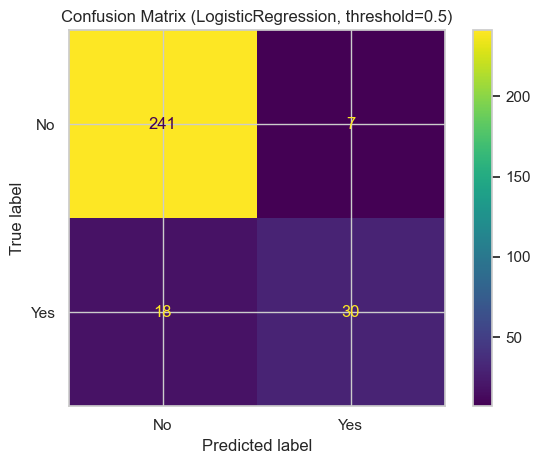

Precision (Yes): 0.8108
Recall (Yes):    0.6250
F1-score (Yes):  0.7059


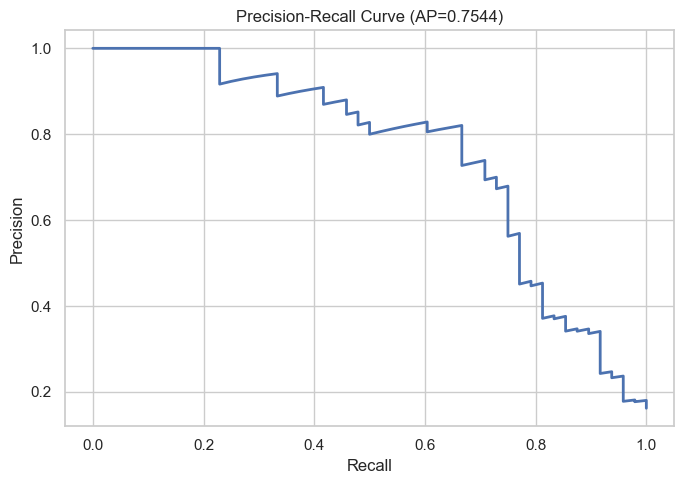

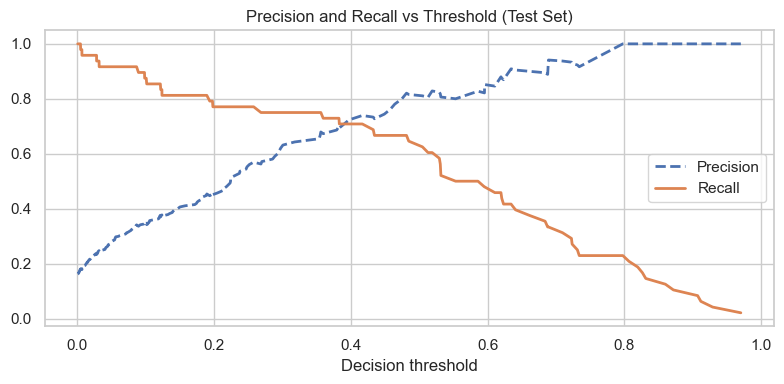

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score,
    precision_recall_curve, average_precision_score
)

# Predictions from the fitted pipeline (from Task 4.1)
y_pred = log_pipe.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No", "Yes"])
plt.figure(figsize=(6, 5))
disp.plot(values_format="d")
plt.title("Confusion Matrix (LogisticRegression, threshold=0.5)")
plt.tight_layout()
plt.show()

# Precision / Recall / F1 (treat 'Yes' as positive)
precision = precision_score(y_test, y_pred, pos_label="Yes")
recall = recall_score(y_test, y_pred, pos_label="Yes")
f1 = f1_score(y_test, y_pred, pos_label="Yes")

print(f"Precision (Yes): {precision:.4f}")
print(f"Recall (Yes):    {recall:.4f}")
print(f"F1-score (Yes):  {f1:.4f}")

# Precision-Recall Curve (need probabilities for the positive class)
y_proba = log_pipe.predict_proba(X_test)[:, 1]  # P(Attrition=Yes)

precisions, recalls, thresholds = precision_recall_curve(
    (y_test == "Yes").astype(int),
    y_proba
)

ap = average_precision_score((y_test == "Yes").astype(int), y_proba)

plt.figure(figsize=(7, 5))
plt.plot(recalls, precisions, linewidth=2)
plt.title(f"Precision-Recall Curve (AP={ap:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.tight_layout()
plt.show()

# Optional: Precision & Recall vs Threshold (very useful for threshold tuning)
plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], linestyle="--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], linestyle="-", label="Recall", linewidth=2)
plt.xlabel("Decision threshold")
plt.title("Precision and Recall vs Threshold (Test Set)")
plt.legend()
plt.tight_layout()
plt.show()


# 6. Imbalance Handling

## Task 6.1: Implementing Class Weights

Address class imbalance by assigning a higher penalty to misclassifying the minority class (Attrition = `Yes`) during model training.

---

### Expected Actions

1. Retrain your LogisticRegression model using the parameter `class_weight='balanced'`.  
2. Evaluate the updated model by comparing the **Recall score** to the baseline model without class weighting.  

---

## Task 6.2: Final Threshold Tuning

Fine-tune the model’s classification threshold to achieve a desired Recall level.

---

### Expected Actions

1. Adjust the **decision threshold** to target a **Recall of 75%**.  
2. Use the **Precision-Recall curve** to identify the corresponding threshold.  
3. Report the final **F1-score** at the tuned threshold.  

---

### <font color="darkred">**Question 5**</font>

- Discuss how threshold tuning affects **Precision, Recall, and overall model performance**.  
- Explain why selecting an appropriate threshold is critical in HR attrition prediction.  

---

Recall comparison (positive class = Attrition 'Yes'):
Baseline LogisticRegression recall: 0.6250
Balanced LogisticRegression recall: 0.7917

Classification report (Balanced LogisticRegression, threshold=0.5):
              precision    recall  f1-score   support

          No     0.9502    0.7702    0.8508       248
         Yes     0.4000    0.7917    0.5315        48

    accuracy                         0.7736       296
   macro avg     0.6751    0.7809    0.6911       296
weighted avg     0.8610    0.7736    0.7990       296


Target Recall: 0.75
Tuned threshold (from validation PR curve): 0.3452
Validation recall at tuned threshold: 0.7447
Validation precision at tuned threshold: 0.2893


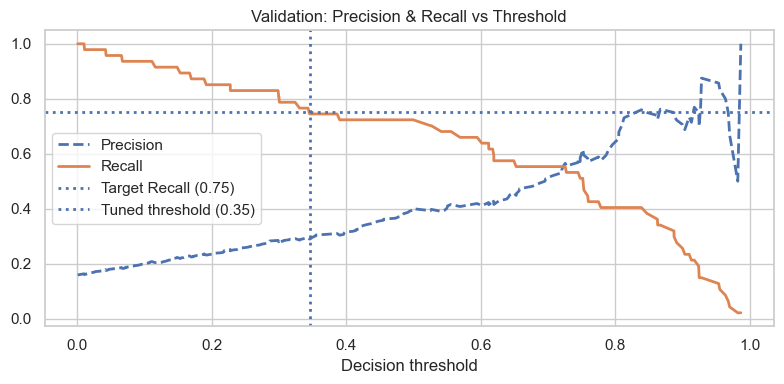


Tuned-threshold performance on TEST set:
Precision (Yes): 0.3500
Recall (Yes):    0.8750
F1-score (Yes):  0.5000

Classification report (Balanced + tuned threshold on TEST):
              precision    recall  f1-score   support

          No     0.9659    0.6855    0.8019       248
         Yes     0.3500    0.8750    0.5000        48

    accuracy                         0.7162       296
   macro avg     0.6580    0.7802    0.6509       296
weighted avg     0.8660    0.7162    0.7529       296



In [8]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import recall_score, precision_score, f1_score, precision_recall_curve, classification_report

# -----------------------------
# Task 6.1: Class weights
# -----------------------------
log_balanced_pipe = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42, class_weight="balanced"))
])

log_balanced_pipe.fit(X_train, y_train)

# Compare Recall on the same test set
y_pred_base = log_pipe.predict(X_test)
y_pred_balanced = log_balanced_pipe.predict(X_test)

recall_base = recall_score(y_test, y_pred_base, pos_label="Yes")
recall_balanced = recall_score(y_test, y_pred_balanced, pos_label="Yes")

print("Recall comparison (positive class = Attrition 'Yes'):")
print(f"Baseline LogisticRegression recall: {recall_base:.4f}")
print(f"Balanced LogisticRegression recall: {recall_balanced:.4f}")

print("\nClassification report (Balanced LogisticRegression, threshold=0.5):")
print(classification_report(y_test, y_pred_balanced, digits=4))

# -----------------------------
# Task 6.2: Threshold tuning to target Recall = 75%
# Use PR curve to find threshold on a validation split (avoid tuning directly on test).
# -----------------------------
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

# Fit balanced model on training split
log_balanced_pipe.fit(X_tr, y_tr)

# Get validation probabilities P(Yes)
val_proba = log_balanced_pipe.predict_proba(X_val)[:, 1]
y_val_bin = (y_val == "Yes").astype(int)

precisions, recalls, thresholds = precision_recall_curve(y_val_bin, val_proba)

target_recall = 0.75

# thresholds has length = len(recalls)-1, so use recalls[:-1]
idx = np.argmin(np.abs(recalls[:-1] - target_recall))
tuned_threshold = thresholds[idx]

print(f"\nTarget Recall: {target_recall:.2f}")
print(f"Tuned threshold (from validation PR curve): {tuned_threshold:.4f}")
print(f"Validation recall at tuned threshold: {recalls[idx]:.4f}")
print(f"Validation precision at tuned threshold: {precisions[idx]:.4f}")

# Plot precision/recall vs threshold on validation
plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], linestyle="--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], linestyle="-", label="Recall", linewidth=2)
plt.axhline(target_recall, linestyle=":", linewidth=2, label="Target Recall (0.75)")
plt.axvline(tuned_threshold, linestyle=":", linewidth=2, label=f"Tuned threshold ({tuned_threshold:.2f})")
plt.title("Validation: Precision & Recall vs Threshold")
plt.xlabel("Decision threshold")
plt.legend()
plt.tight_layout()
plt.show()

# Evaluate tuned threshold on TEST set (report final F1-score)
test_proba = log_balanced_pipe.predict_proba(X_test)[:, 1]
y_pred_tuned = np.where(test_proba >= tuned_threshold, "Yes", "No")

precision_tuned = precision_score(y_test, y_pred_tuned, pos_label="Yes")
recall_tuned = recall_score(y_test, y_pred_tuned, pos_label="Yes")
f1_tuned = f1_score(y_test, y_pred_tuned, pos_label="Yes")

print("\nTuned-threshold performance on TEST set:")
print(f"Precision (Yes): {precision_tuned:.4f}")
print(f"Recall (Yes):    {recall_tuned:.4f}")
print(f"F1-score (Yes):  {f1_tuned:.4f}")

print("\nClassification report (Balanced + tuned threshold on TEST):")
print(classification_report(y_test, y_pred_tuned, digits=4))

# Quick discussion points for Question 5 (write in your own words in the report):
# - Increasing recall typically decreases precision (more false positives).
# - In HR attrition, higher recall means catching more leavers, enabling early intervention,
#   but may flag more employees who would not leave (cost of unnecessary actions).
